In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


In [3]:
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df = df.drop_duplicates().copy()

X = df.drop(columns=["Outcome"])
y = df["Outcome"]


cols = [
    "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI"
]

X[cols] = X[cols].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")
X[cols] = imputer.fit_transform(X[cols])

print("Missing values after preprocessing:", X.isnull().sum().sum())

Missing values after preprocessing: 0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Normalization completed.")

Normalization completed.


In [7]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("KNN model trained successfully.")

KNN model trained successfully.


In [8]:
cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Confusion Matrix:\n", cm)
print("Accuracy:", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Confusion Matrix:
 [[83 17]
 [21 33]]
Accuracy: 0.7532
Error Rate: 0.2468
Precision: 0.66
Recall: 0.6111
F1 Score: 0.6346


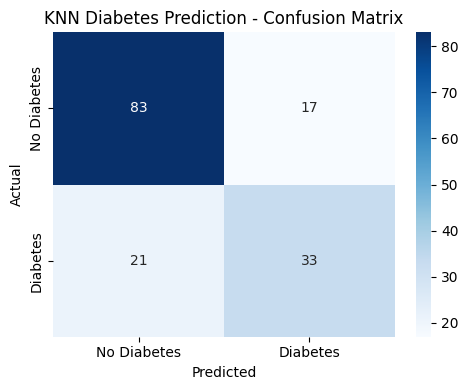

In [9]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Diabetes Prediction - Confusion Matrix")
plt.tight_layout()
plt.savefig("diabetes_confusion_matrix.png", dpi=200)
plt.show()

In [10]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy", "Error Rate",
        "Precision", "Recall", "F1 Score"
    ],
    "Value": [
        accuracy, error_rate, precision, recall, f1
    ]
})

results["Value"] = results["Value"].round(4)

display(results)

,Metric,Value
0,Accuracy,0.7532
1,Error Rate,0.2468
2,Precision,0.6600
3,Recall,0.6111
4,F1 Score,0.6346


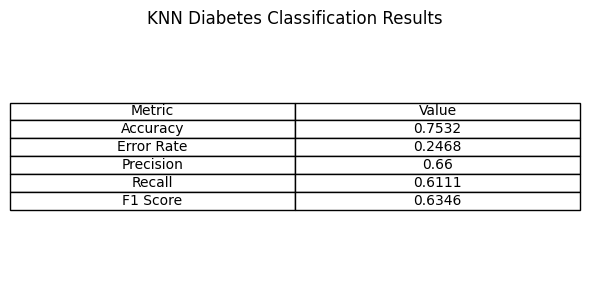

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from google.colab import files

plt.figure(figsize=(6, 3))
plt.axis("off")

plt.table(
    cellText=results.values,
    colLabels=results.columns,
    loc="center",
    cellLoc="center"
)

plt.title("KNN Diabetes Classification Results")
plt.tight_layout()
plt.savefig("diabetes_results.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("diabetes_results.png")
files.download("diabetes_confusion_matrix.png")